# 10 — Time to termination (competing risks)

**Question:** Once a trial starts, how soon does it end in termination for low enrollment, termination for another
reason, or completion? Later sections ask which start-time characteristics change the risk of each.

A trial that completes, or stops for another reason, can no longer be terminated for low enrollment. These are
competing risks, so 1 − Kaplan–Meier would overstate the risk of each outcome. We estimate cumulative incidence
(Aalen–Johansen) instead, and the models will be cause-specific Cox models (`statsmodels` `PHReg`).

**Stop reasons are still v0**, the keyword rules in `scripts/03_build_dataset.py`. Once notebook 07 validates the
LLM labels, point `REASON_COL` at the new column and rerun.

**Inputs:** `data/processed/trials.parquet` (status, stop reason, start-time features) and
`data/raw/studies.parquet` (completion and verification dates).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "notebooks" / "figures"

REASON_COL = "stop_reason"     # v0 keyword labels
UNKNOWN_HANDLING = "censor"    # "censor" or "exclude"; see section 3
MONTH = 30.4375
OUTCOMES = {1: "terminated: enrollment", 2: "terminated: other", 3: "completed"}
COLORS = {1: "#2a78d6", 2: "#eb6834"}

trials = pd.read_parquet(ROOT / "data/processed/trials.parquet",
                         columns=["nct_id", "overall_status", REASON_COL, "phase", "lead_sponsor_class", "start_year"])
dates = pd.read_parquet(ROOT / "data/raw/studies.parquet",
                        columns=["nct_id", "start_date", "completion_date", "completion_date_type", "verification_date"])
for c in ["start_date", "completion_date", "verification_date"]:
    dates[c] = pd.to_datetime(dates[c])
df = trials.merge(dates, on="nct_id", how="left")
print(f"{len(df):,} trials")

231,776 trials


## 1. Outcome and time

| Status | Role | End of follow-up |
|---|---|---|
| TERMINATED, stop reason `enrollment` | outcome 1 | actual completion date |
| TERMINATED, any other reason (including none given) | outcome 2 | actual completion date |
| COMPLETED | outcome 3 | actual completion date |
| RECRUITING, ACTIVE_NOT_RECRUITING, ENROLLING_BY_INVITATION, SUSPENDED | censored | verification date |
| UNKNOWN | censored or excluded (section 3) | verification date |
| WITHDRAWN, NOT_YET_RECRUITING | excluded: never enrolled anyone | |

Time runs from `start_date`. The verification date is the last date the sponsor confirmed the trial's status, so a
censored trial is known to be still running up to that date.

For terminated trials, the completion date is when the last participant was seen, which can be months after the
decision to stop. Time to termination is measured to that date.

In [2]:
def build(df, unknown="censor"):
    d = df[~df["overall_status"].isin(["WITHDRAWN", "NOT_YET_RECRUITING"])].copy()
    if unknown == "exclude":
        d = d[d["overall_status"] != "UNKNOWN"]
    status = d["overall_status"]
    ended = status.isin(["COMPLETED", "TERMINATED"])
    d["outcome"] = np.select([status.eq("TERMINATED") & d[REASON_COL].eq("enrollment"),
                              status.eq("TERMINATED"), status.eq("COMPLETED")], [1, 2, 3], default=0)
    actual_end = d["completion_date"].where(d["completion_date_type"].eq("ACTUAL"))
    d["end_date"] = actual_end.where(ended, d["verification_date"])
    d["months"] = (d["end_date"] - d["start_date"]).dt.days / MONTH
    return d

full = build(df, unknown="censor")
flow = full.groupby("overall_status").agg(
    trials=("nct_id", "size"),
    no_actual_end_date=("end_date", lambda s: s.isna().sum()),
    ends_on_or_before_start=("months", lambda s: (s <= 0).sum()),
    analyzed=("months", lambda s: (s > 0).sum()),
)
flow.loc["total"] = flow.sum()
flow

,trials,no_actual_end_date,ends_on_or_before_start,analyzed
overall_status,,,,
ACTIVE_NOT_RECRUITING,4982,0,2,4980
COMPLETED,156707,1732,516,154459
ENROLLING_BY_INVITATION,215,0,1,214
RECRUITING,3017,0,15,3002
SUSPENDED,647,0,57,590
TERMINATED,20039,510,49,19480
UNKNOWN,37943,0,10282,27661
total,223550,2242,10922,210386


Completed and terminated trials without an actual completion date, and records whose end date is on or before
the start date, are dropped. For UNKNOWN trials, "ends on or before start" means the record was last verified before
the trial's planned start, so it was never seen running.

In [3]:
surv = build(df, UNKNOWN_HANDLING)
surv = surv[surv["months"] > 0].copy()
counts = surv["outcome"].map({0: "censored", **OUTCOMES}).value_counts()
print(f"{len(surv):,} trials analyzed (UNKNOWN: {UNKNOWN_HANDLING})")
print(counts.to_string())
print("\nMonths from start to end of follow-up:")
surv.groupby(surv["outcome"].map({0: "censored", **OUTCOMES}))["months"].describe(percentiles=[.25, .5, .75]).round(1)

210,386 trials analyzed (UNKNOWN: censor)
outcome
completed                 154459
censored                   36447
terminated: other          11762
terminated: enrollment      7718

Months from start to end of follow-up:


,count,mean,std,min,25%,50%,75%,max
outcome,,,,,,,,
censored,36447.0,39.7,40.0,0.0,7.6,26.0,64.5,222.1
completed,154459.0,30.5,26.1,0.0,11.0,23.5,43.0,220.2
terminated: enrollment,7718.0,35.8,24.5,0.1,18.0,30.5,48.0,215.5
terminated: other,11762.0,32.5,24.4,0.0,14.0,27.0,45.0,208.0


## 2. Cumulative incidence

The Aalen–Johansen estimate gives the share of trials that have ended each way by a given time, after allowing for
censoring and for the competing outcomes.

In [4]:
def cumulative_incidence(months, outcome):
    counts = pd.crosstab(months, outcome)
    at_risk = counts.sum(axis=1)[::-1].cumsum()[::-1]
    events = counts.drop(columns=0, errors="ignore")
    surv_before = (1 - events.sum(axis=1) / at_risk).cumprod().shift(fill_value=1.0)
    return events.div(at_risk, axis=0).mul(surv_before, axis=0).cumsum()

def at_years(cif, years):
    idx = cif.index.searchsorted(np.asarray(years) * 12, side="right") - 1
    return cif.iloc[idx].set_axis([f"{y} yr" for y in years])

YEARS = [1, 2, 3, 5, 10]
cif = cumulative_incidence(surv["months"], surv["outcome"])
(at_years(cif, YEARS).rename(columns=OUTCOMES) * 100).round(1).T

,1 yr,2 yr,3 yr,5 yr,10 yr
outcome,,,,,
terminated: enrollment,0.5,1.5,2.4,3.6,4.3
terminated: other,1.2,2.7,3.9,5.5,6.5
completed,21.4,40.0,53.6,71.2,84.8


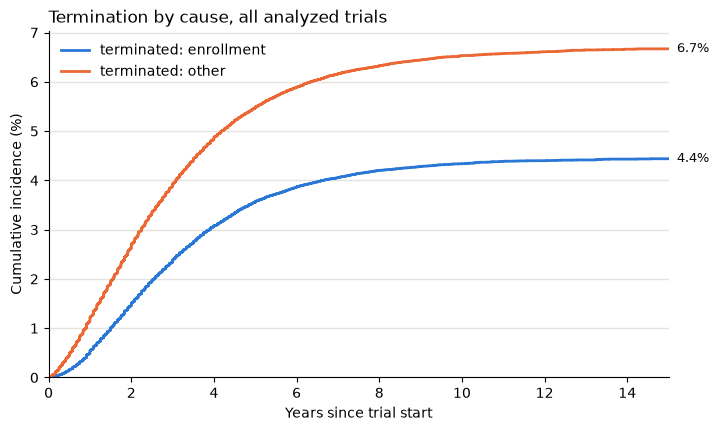

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
END = 15
for k in [1, 2]:
    y = cif[k] * 100
    ax.step(y.index / 12, y, where="post", color=COLORS[k], lw=2, label=OUTCOMES[k])
    end = at_years(cif, [END])[k].iloc[0] * 100
    ax.annotate(f"{end:.1f}%", (END, end), xytext=(6, 0), textcoords="offset points", va="center",
                fontsize=9, color="#0b0b0b", annotation_clip=False)
ax.set_xlim(0, END)
ax.set_ylim(0, None)
ax.set_xlabel("Years since trial start")
ax.set_ylabel("Cumulative incidence (%)")
ax.set_title("Termination by cause, all analyzed trials", loc="left")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", color="#e4e3df", lw=1)
ax.grid(axis="x", visible=False)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.savefig(FIG / "survival_cumulative_incidence.png", bbox_inches="tight", dpi=110)
plt.show()

## 3. Decision: what to do with UNKNOWN trials

ClinicalTrials.gov marks a trial UNKNOWN when it was last reported as recruiting, active or not yet recruiting and
the record hasn't been verified for more than two years. They are 16% of the cohort.

- **Censor at the verification date** (current setting). This uses the time they were known to be running. It
  assumes that trials which stopped reporting end the same way as similar trials that kept reporting. That's
  doubtful: a sponsor that stops updating the record may be more likely to have quietly abandoned the trial, which
  would make the incidence of termination look too low.
- **Exclude them.** This only describes trials whose sponsors kept the record up to date, and throws away the time
  they were known to be running.
- **Make "stopped reporting" a fourth outcome** at the verification date. Then the curves also describe how often
  sponsors abandon the record.

The table shows how much the first two options change the estimates.

In [6]:
compare = {}
for option in ["censor", "exclude"]:
    d = build(df, option)
    d = d[d["months"] > 0]
    c = at_years(cumulative_incidence(d["months"], d["outcome"]), [3, 5, 10])[[1, 2]]
    c.columns = [OUTCOMES[k] for k in c.columns]
    compare[f"{option} ({len(d):,} trials)"] = (c * 100).round(2).stack()
pd.DataFrame(compare)

censor (210,386 trials)  \
3 yr  terminated: enrollment                     2.36   
      terminated: other                          3.89   
5 yr  terminated: enrollment                     3.57   
      terminated: other                          5.48   
10 yr terminated: enrollment                     4.34   
      terminated: other                          6.53   

                              exclude (182,725 trials)  
3 yr  terminated: enrollment                      2.49  
      terminated: other                           4.13  
5 yr  terminated: enrollment                      3.64  
      terminated: other                           5.65  
10 yr terminated: enrollment                      4.31  
      terminated: other                           6.57

**Decision:** _to fill in_

## 4. By phase and sponsor

Five-year cumulative incidence of each kind of termination within each group. `NA` phase means the trial is not a
drug trial with phases (device, behavioral and procedure trials).

In [7]:
def five_year_by(col, min_n=500):
    rows = {}
    for group, d in surv.groupby(surv[col].fillna("missing")):
        if len(d) < min_n:
            continue
        c = at_years(cumulative_incidence(d["months"], d["outcome"]), [5]).iloc[0]
        rows[group] = {"trials": len(d), **{OUTCOMES[k]: round(c.get(k, 0) * 100, 2) for k in [1, 2]}}
    return pd.DataFrame(rows).T.astype({"trials": int}).sort_values(OUTCOMES[1])

by_phase = five_year_by("phase")
display(by_phase)
display(five_year_by("lead_sponsor_class"))

,trials,terminated: enrollment,terminated: other
PHASE1,24376,2.32,7.02
NA,104443,2.87,3.53
PHASE3,19490,3.21,6.82
PHASE2/PHASE3,3634,3.63,7.11
PHASE1/PHASE2,7815,4.34,10.16
EARLY_PHASE1,2681,4.57,6.89
PHASE4,18218,5.19,4.78
PHASE2,29645,5.97,8.74


,trials,terminated: enrollment,terminated: other
OTHER_GOV,4692,2.00,2.34
INDUSTRY,55193,2.61,8.51
FED,2150,3.49,3.92
OTHER,144303,3.97,4.33
NIH,2355,4.55,7.24
NETWORK,1380,5.48,3.41


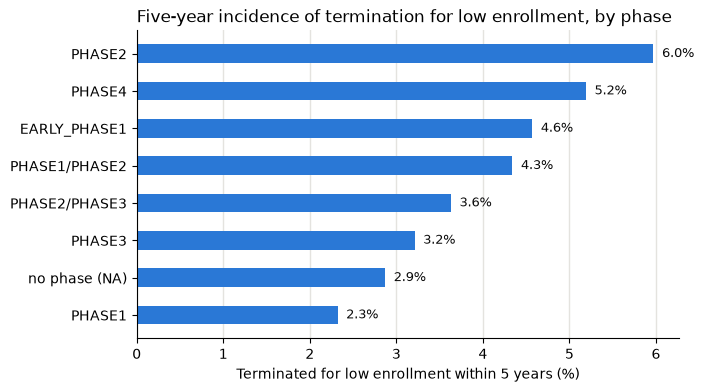

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
y = by_phase[OUTCOMES[1]].astype(float).rename(index={"NA": "no phase (NA)"})
ax.barh(y.index, y, height=0.5, color=COLORS[1])
for i, v in enumerate(y):
    ax.text(v + 0.1, i, f"{v:.1f}%", va="center", fontsize=9, color="#0b0b0b")
ax.set_xlabel("Terminated for low enrollment within 5 years (%)")
ax.set_title("Five-year incidence of termination for low enrollment, by phase", loc="left")
ax.grid(axis="x", color="#e4e3df", lw=1)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.savefig(FIG / "survival_by_phase.png", bbox_inches="tight", dpi=110)
plt.show()

## 5. Still to do

1. Decide how to handle UNKNOWN trials (section 3).
2. Fit cause-specific Cox models for outcomes 1 and 2 with the start-time features from notebook 05 (design,
   disease area, eligibility features), and compare which features change each hazard. Only features known at the
   start can go in (see the leakage warning in the README).
3. After notebook 07, switch `REASON_COL` to the validated stop reasons and rerun.